Загрузка датасета

In [258]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import numpy as np

df = pd.read_csv('../data/AmesHousing.csv')

Изучение распределения целевой переменной saleprice

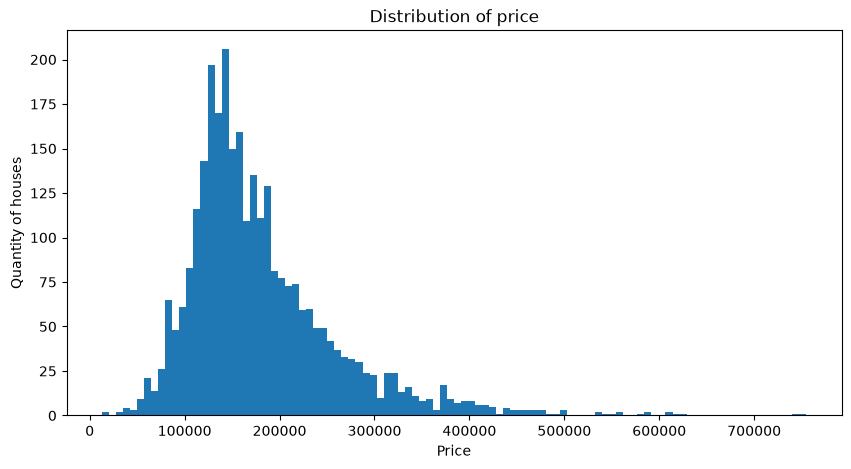

In [259]:
df = df.drop(columns=['Order', 'PID']) # Служебные столбцы
df.columns = df.columns.str.lower().str.replace(' ', '_')
plt.figure(figsize=(10, 5))
plt.hist(df['saleprice'], bins=100)
plt.title('Distribution of price')
plt.xlabel('Price')
plt.ylabel('Quantity of houses')
plt.show()

In [260]:
print(df['saleprice'].skew(), '\n', df['saleprice'].kurt(),
      '\n', stats.shapiro(df['saleprice']))
# Тяжелый хвост справа, данные не нормальны

1.7435000757376475 
 5.1188999511308975 
 ShapiroResult(statistic=np.float64(0.8762606264935351), pvalue=np.float64(2.3349088329079337e-43))


In [ ]:
print(df['saleprice'][df['saleprice'] < 50000].sort_values(), '\n')
print(df['saleprice'][df['saleprice'] > 580000].sort_values())

181     12789
1553    13100
726     34900
2843    35000
2880    35311
709     37900
1901    39300
1555    40000
727     44000
708     45000
1302    46500
Name: saleprice, dtype: int64 

433     582933
2450    584500
1637    591587
432     610000
44      611657
1063    615000
2445    625000
1760    745000
1767    755000
Name: saleprice, dtype: int64


Анализ значений, похожих на выбросы

In [262]:
# Создам список наиболее важных признаков для удобства анализа
features = ['lot_area', 'overall_qual', 'year_built', 'total_bsmt_sf',
            'gr_liv_area', 'garage_area', 'saleprice']

print(df[features][df['saleprice'] == 12789.0].T)
print(df[features][df['saleprice'] == 755000.0].T)
# Признаки в норме, похожих значений в saleprice много, это не выбросы

                   181
lot_area        9656.0
overall_qual       2.0
year_built      1923.0
total_bsmt_sf    678.0
gr_liv_area      832.0
garage_area      780.0
saleprice      12789.0
                   1767
lot_area        21535.0
overall_qual       10.0
year_built       1994.0
total_bsmt_sf    2444.0
gr_liv_area      4316.0
garage_area       832.0
saleprice      755000.0


In [263]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ms_subclass,2930.0,57.387372,42.638025,20.0,20.00,50.0,70.00,190.0
lot_frontage,2440.0,69.224590,23.365335,21.0,58.00,68.0,80.00,313.0
lot_area,2930.0,10147.921843,7880.017759,1300.0,7440.25,9436.5,11555.25,215245.0
overall_qual,2930.0,6.094881,1.411026,1.0,5.00,6.0,7.00,10.0
overall_cond,2930.0,5.563140,1.111537,1.0,5.00,5.0,6.00,9.0
year_built,2930.0,1971.356314,30.245361,1872.0,1954.00,1973.0,2001.00,2010.0
year_remod/add,2930.0,1984.266553,20.860286,1950.0,1965.00,1993.0,2004.00,2010.0
mas_vnr_area,2907.0,101.896801,179.112611,0.0,0.00,0.0,164.00,1600.0
bsmtfin_sf_1,2929.0,442.629566,455.590839,0.0,0.00,370.0,734.00,5644.0
bsmtfin_sf_2,2929.0,49.722431,169.168476,0.0,0.00,0.0,0.00,1526.0


Признак lot_area распределен подозрительно, среднее больше медианы в ~10,5 раз, построю график распределения и подробнее изучу признак

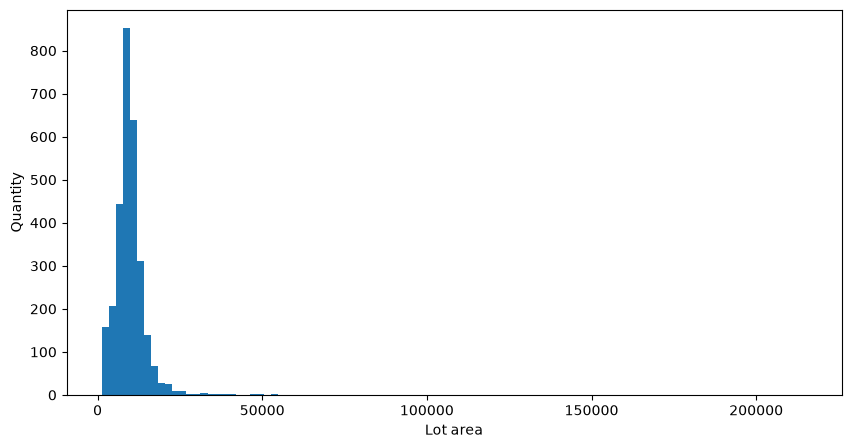

In [264]:
plt.figure(figsize=(10, 5))
plt.hist(df['lot_area'], bins=100)
plt.xlabel('Lot area')
plt.ylabel('Quantity')
plt.show()

In [265]:
print(df['lot_area'].skew(), '\n', df['lot_area'].kurt())
# Очень тяжелые хвосты

12.820898171092686 
 265.02367060293284


In [266]:
print(df[['lot_area', 'saleprice']][df['lot_area'] < 1500].sort_values('saleprice')) # маленькое значение lot_area в датасете не редкость
print(df[features][df['lot_area'] == 1300.0].T) # похожих значений много, признаки в норме, не выброс

      lot_area  saleprice
2913      1470      73000
330       1491      75500
329       1476      76000
2914      1484      79400
977       1477      80000
2287      1495      93900
1599      1477      98000
935       1300     124000
933       1488     137000
                    935
lot_area         1300.0
overall_qual        6.0
year_built       1980.0
total_bsmt_sf     561.0
gr_liv_area      1229.0
garage_area       462.0
saleprice      124000.0


In [267]:
q1 = df['lot_area'].quantile(0.25)
q3 = df['lot_area'].quantile(0.75)
iqr = q3 - q1
upper = q3 + 3*iqr
print(upper, '— верхняя граница по правилу 3 IQR, после которой идут статистические выбросы\n')
print((df['lot_area'] > upper).sum(), '— количество таких выбросов. Проверю природу некоторых из них')
# print(df['lot_area'][df['lot_area'] > upper]) - все выбросы по правилу 3 IQR

23900.25 — верхняя граница по правилу 3 IQR, после которой идут статистические выбросы

53 — количество таких выбросов. Проверю природу некоторых из них


In [268]:
print(df[features][df['lot_area'] == 31770].T)
print(df[features][df['lot_area'] == 215245].T)
# Очевидных причин по которым эти записи можно отнести к выбросам нет, поэтому удалять их не стану
# В дальнейшем проведу анализ, насколько модели справляются со всем признаком

                      0
lot_area        31770.0
overall_qual        6.0
year_built       1960.0
total_bsmt_sf    1080.0
gr_liv_area      1656.0
garage_area       528.0
saleprice      215000.0
                    956
lot_area       215245.0
overall_qual        7.0
year_built       1965.0
total_bsmt_sf    2136.0
gr_liv_area      2036.0
garage_area       513.0
saleprice      375000.0


Поиск наиболее коррелирующих признаков

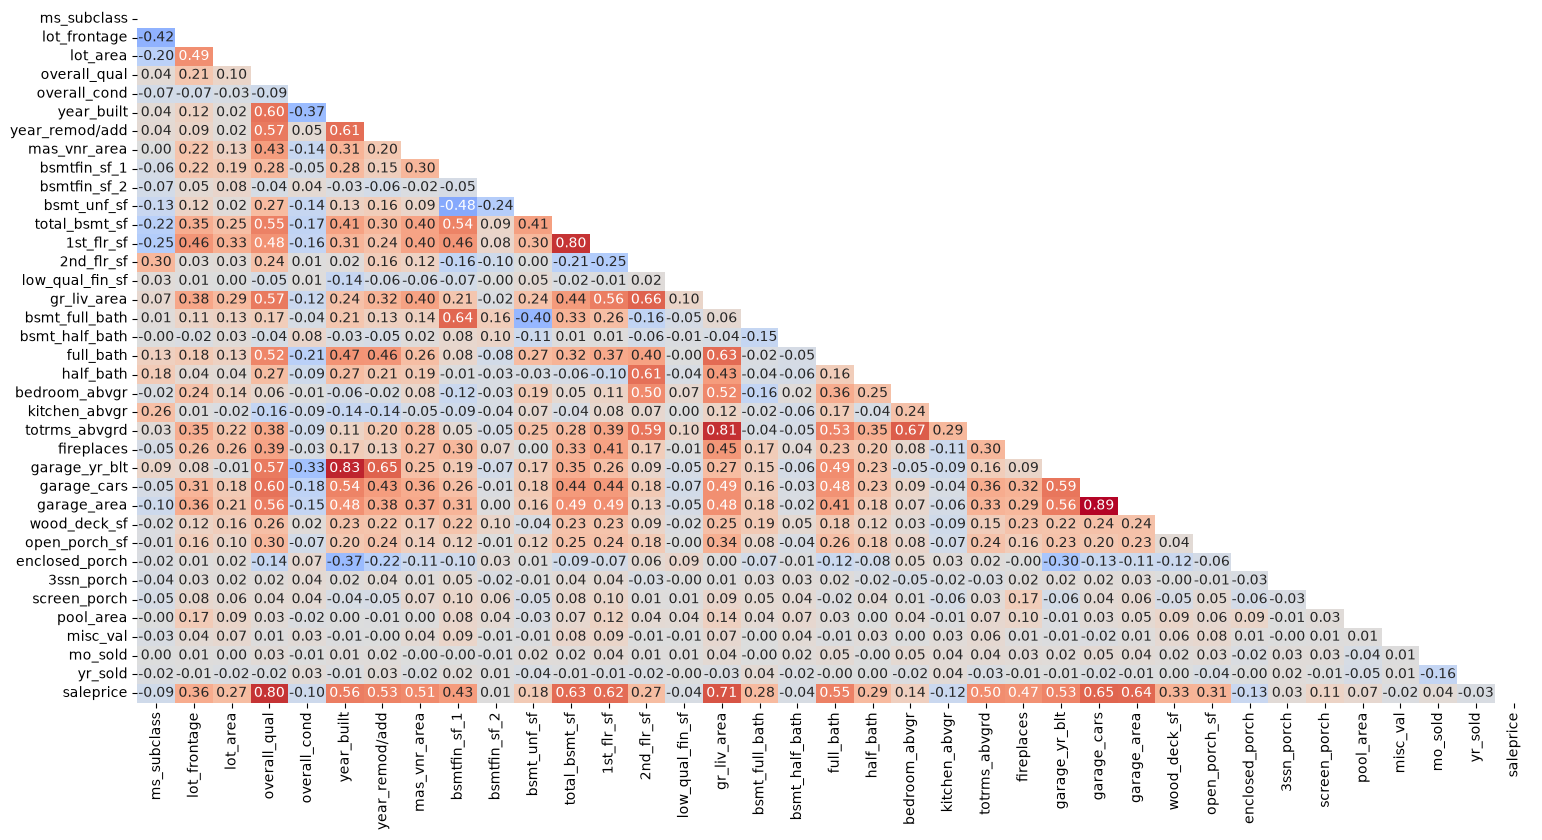

In [269]:
corr = df.corr(numeric_only=True)
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(18, 9))
sns.heatmap(corr, cmap='coolwarm', annot=True, fmt='.2f',
            center=0, mask=mask, cbar=False)
plt.show()

In [270]:
# Создам список пар коллинеарных признаков с порогом корреляции 0.8
coll = [['1st_flt_sf', 'total_bsmt_sf', 0.80], ['garage_yr_blt', 'year_built', 0.83],
        ['totrms_abvgrd', 'gr_liv_area', 0.81], ['garage_area', 'garage_cars', 0.89]]

Анализ пропусков и поиск категориальных столбцов

In [271]:
metrics = pd.DataFrame({
    'dtypes': df.dtypes,
    'missing_%': df.isna().mean() * 100,
    'missing': df.isna().sum(),
    'nunique': df.nunique()
}).sort_values('nunique')
print(metrics[metrics['dtypes'] == 'int64'])
print(metrics[metrics['dtypes'] == 'float64'])
print(metrics[metrics['dtypes'] == 'str'])

                dtypes  missing_%  missing  nunique
half_bath        int64        0.0        0        3
kitchen_abvgr    int64        0.0        0        4
full_bath        int64        0.0        0        5
fireplaces       int64        0.0        0        5
yr_sold          int64        0.0        0        5
bedroom_abvgr    int64        0.0        0        8
overall_cond     int64        0.0        0        9
overall_qual     int64        0.0        0       10
mo_sold          int64        0.0        0       12
totrms_abvgrd    int64        0.0        0       14
pool_area        int64        0.0        0       14
ms_subclass      int64        0.0        0       16
3ssn_porch       int64        0.0        0       31
low_qual_fin_sf  int64        0.0        0       36
misc_val         int64        0.0        0       38
year_remod/add   int64        0.0        0       61
year_built       int64        0.0        0      118
screen_porch     int64        0.0        0      121
enclosed_por

In [272]:
missing48 = (metrics.index[metrics['missing_%'] > 48]).to_list()
print(missing48, '\n— признаки, количество пропусков в которых превышает 48%')

['alley', 'mas_vnr_type', 'pool_qc', 'fence', 'misc_feature', 'fireplace_qu'] 
— признаки, количество пропусков в которых превышает 48%


In [277]:
for i in missing48:
    print(df[i].unique(), f'=== {i.upper()}, missing: {metrics['missing_%'][i].round(2)}%')
# В данном случае NaN - не пропуск, а отсутствие конкретного объекта.
# Проверю остальные категориальные признаки где пропусков 1% < x <48%

<StringArray>
[nan, 'Pave', 'Grvl']
Length: 3, dtype: str === ALLEY, missing: 93.24%
<StringArray>
['Stone', nan, 'BrkFace', 'BrkCmn', 'CBlock']
Length: 5, dtype: str === MAS_VNR_TYPE, missing: 60.58%
<StringArray>
[nan, 'Ex', 'Gd', 'TA', 'Fa']
Length: 5, dtype: str === POOL_QC, missing: 99.56%
<StringArray>
[nan, 'MnPrv', 'GdPrv', 'GdWo', 'MnWw']
Length: 5, dtype: str === FENCE, missing: 80.48%
<StringArray>
[nan, 'Gar2', 'Shed', 'Othr', 'Elev', 'TenC']
Length: 6, dtype: str === MISC_FEATURE, missing: 96.38%
<StringArray>
['Gd', nan, 'TA', 'Po', 'Ex', 'Fa']
Length: 6, dtype: str === FIREPLACE_QU, missing: 48.53%


In [278]:
missing1 = metrics.index[(metrics['dtypes'] == 'str')\
                & (metrics['missing_%'] < 48) & (metrics['missing_%'] > 1)].to_list()
for i in missing1:
    print(df[i].unique(), f'=== {i.upper()}, missing: {metrics['missing_%'][i].round(2)}%')
# Это уже реальные пропуски, а не отсутствие конкретного объекта при доме. В препроцессинге заменю значения на 'Missing'

<StringArray>
['Fin', 'Unf', 'RFn', nan]
Length: 4, dtype: str === GARAGE_FINISH, missing: 5.43%
<StringArray>
['Gd', 'No', 'Mn', 'Av', nan]
Length: 5, dtype: str === BSMT_EXPOSURE, missing: 2.83%
<StringArray>
['TA', nan, 'Fa', 'Gd', 'Ex', 'Po']
Length: 6, dtype: str === GARAGE_COND, missing: 5.43%
<StringArray>
['Gd', 'TA', nan, 'Po', 'Fa', 'Ex']
Length: 6, dtype: str === BSMT_COND, missing: 2.73%
<StringArray>
['TA', 'Gd', 'Ex', nan, 'Fa', 'Po']
Length: 6, dtype: str === BSMT_QUAL, missing: 2.73%
<StringArray>
['TA', nan, 'Fa', 'Gd', 'Ex', 'Po']
Length: 6, dtype: str === GARAGE_QUAL, missing: 5.43%
<StringArray>
['Unf', 'LwQ', 'BLQ', 'Rec', nan, 'GLQ', 'ALQ']
Length: 7, dtype: str === BSMTFIN_TYPE_2, missing: 2.76%
<StringArray>
['Attchd', 'BuiltIn', 'Basment', 'Detchd', nan, 'CarPort', '2Types']
Length: 7, dtype: str === GARAGE_TYPE, missing: 5.36%
<StringArray>
['BLQ', 'Rec', 'ALQ', 'GLQ', 'Unf', 'LwQ', nan]
Length: 7, dtype: str === BSMTFIN_TYPE_1, missing: 2.73%
